# Cardiac Arrhythmia Detection
## CNN vs DenseNet vs DenseNet + Multi-Scale Multi-Head Attention, with Grad-CAM region analysis
**Dataset**: MIT-BIH Arrhythmia (via Kaggle `shayanfazeli/heartbeat`, resampled to 125 Hz, beats start at the R-peak)  
**What this notebook does**:
1. Three models are compared: a baseline CNN, a DenseNet with transition layers, and a DenseNet with two multi-head attention blocks at different temporal scales
2. SpatialDropout1D in conv layers
3. ECG-aware augmentation (time-shift, amplitude scaling, Gaussian noise) on the minority classes
4. Class-weighted training and a clinical-priority score (Ventricular > SVT > Fusion > accuracy) for model selection
5. Grad-CAM attention summarised per ECG region, averaged over correctly classified test beats

**Limitations**: the Kaggle train and test files are split by beat, not by patient, so beats from the same patient can appear on both sides. Reported accuracy is therefore optimistic. The attention model did not beat the plain DenseNet in this run.


# ***Install & Imports***

In [13]:
import kagglehub
path = kagglehub.dataset_download('shayanfazeli/heartbeat')
print('Dataset path:', path)

Dataset path: /kaggle/input/datasets/shayanfazeli/heartbeat


In [14]:
# ──────────────────────────────────────────────────────────────
# CORE IMPORTS
# NumPy / Pandas for data handling
# TensorFlow/Keras for model building
# Sklearn for metrics and class-weight computation
# ──────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization, MaxPooling1D,
    Dense, Dropout, SpatialDropout1D, Flatten, Concatenate,
    GlobalAveragePooling1D, Add, MultiHeadAttention, LayerNormalization
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from sklearn.utils import shuffle
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# ── Reproducibility seeds ──────────────────────────────────────
# Setting seeds ensures the same random weight initialisation,
# data shuffling, and dropout masks every run — essential for
# reproducible results across runs.
tf.random.set_seed(42)
np.random.seed(42)

# ── Class metadata ─────────────────────────────────────────────
# MIT-BIH has 5 AAMI-EC57 classes:
# N=Normal, S=Supraventricular, V=Ventricular, F=Fusion, Q=Unknown
CLASS_NAMES = ['Normal', 'Supraventricular', 'Ventricular', 'Fusion', 'Unknown']
COLORS      = ['#1565C0', '#E65100', '#B71C1C', '#00695C', '#6A1B9A']
NUM_CLASSES = 5

print(f'TensorFlow {tf.__version__}')
print(f' GPU: {tf.config.list_physical_devices("GPU")}')

TensorFlow 2.19.0
 GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


# **Load MIT-BIH Dataset**

In [15]:
# ──────────────────────────────────────────────────────────────
# DATA LOADING
# MIT-BIH CSV: columns 0-186 = 187 time-steps of ECG amplitude
#              column 187    = integer class label (0-4)
# Each row is one heartbeat segment resampled to 125 Hz, so 187 samples ≈ 1.5 s. Each beat starts at the R-peak and is zero-padded
# ──────────────────────────────────────────────────────────────
train_df = pd.read_csv('/kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_train.csv', header=None)
test_df  = pd.read_csv('/kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_test.csv',  header=None)

X_train_raw = train_df.iloc[:, :187].values.astype(np.float32)
y_train_raw = train_df.iloc[:, 187].values.astype(int)
X_test_raw  = test_df.iloc[:, :187].values.astype(np.float32)
y_test      = test_df.iloc[:, 187].values.astype(int)

print(f'Train: {X_train_raw.shape} | Test: {X_test_raw.shape}')
print('\n=== CLASS DISTRIBUTION (TRAIN) ===')
for i, name in enumerate(CLASS_NAMES):
    n   = np.sum(y_train_raw == i)
    bar = '█' * int(n / 2000)
    print(f'  {name:20s}: {n:6d}  ({n/len(y_train_raw)*100:.1f}%)  {bar}')
# NOTE: Class imbalance is extreme — Normal is ~83% of data.
# This is why class_weight and clinical-priority metrics matter more
# than raw accuracy.

Train: (87554, 187) | Test: (21892, 187)

=== CLASS DISTRIBUTION (TRAIN) ===
  Normal              :  72471  (82.8%)  ████████████████████████████████████
  Supraventricular    :   2223  (2.5%)  █
  Ventricular         :   5788  (6.6%)  ██
  Fusion              :    641  (0.7%)  
  Unknown             :   6431  (7.3%)  ███


# **Visualise Sample Beats**

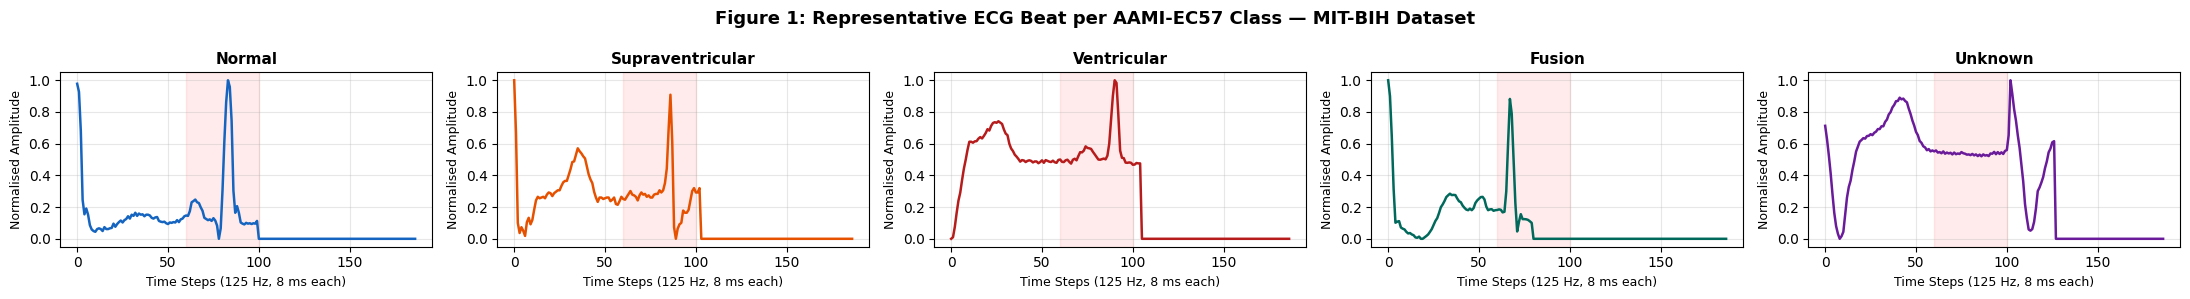

In [16]:
# ──────────────────────────────────────────────────────────────
# SAMPLE BEAT VISUALISATION
# One representative beat per class, plotted side-by-side.
# Shows how morphology differs between classes.
# ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 5, figsize=(22, 3))
for i, (name, color) in enumerate(zip(CLASS_NAMES, COLORS)):
    idx = np.where(y_train_raw == i)[0][0]
    axes[i].plot(X_train_raw[idx], color=color, linewidth=1.8)
    axes[i].set_title(name, fontweight='bold', fontsize=11)
    axes[i].set_xlabel('Time Steps (125 Hz, 8 ms each)', fontsize=9)
    axes[i].set_ylabel('Normalised Amplitude', fontsize=9)
    axes[i].grid(alpha=0.3)
    # Annotate QRS peak region (approx timesteps 60-100)
    axes[i].axvspan(60, 100, alpha=0.08, color='red', label='QRS region')
plt.suptitle('Figure 1: Representative ECG Beat per AAMI-EC57 Class — MIT-BIH Dataset',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig1_sample_beats.png', dpi=300, bbox_inches='tight')
plt.show()

# **Preprocessing & Augmentation**

In [17]:
# ──────────────────────────────────────────────────────────────
# ECG-AWARE DATA AUGMENTATION
# Why augment? Fusion class has only ~800 samples vs 72k Normal.
# Augmentation is clinically valid because:
#   1. Time-shift: small alignment offsets happen naturally in real ECGs
#   2. Amplitude scaling: electrode placement variation changes amplitude
#   3. Gaussian noise: sensor noise is always present in real recordings
#
# Applied ONLY to minority classes (S, V, F) to balance the dataset.
# NOT applied to test set — augmentation is a training-time tool only.
# ──────────────────────────────────────────────────────────────

def augment_beat(signal, shift_range=10, scale_range=0.12, noise_std=0.01):
    """
    Apply three ECG-valid augmentations to a single 187-timestep beat.
    
    Args:
        signal      : 1D array of length 187
        shift_range : max time-shift in timesteps (±10 = ±80ms at 125Hz)
        scale_range : amplitude scaling ± this fraction
        noise_std   : standard deviation of additive Gaussian noise
    Returns:
        Augmented signal of same length 187
    """
    # 1. Random time-shift — roll the signal and zero-pad the wrapped edge
    shift = np.random.randint(-shift_range, shift_range)
    aug   = np.roll(signal, shift)
    if shift > 0:
        aug[:shift] = 0.0
    elif shift < 0:
        aug[shift:] = 0.0

    # 2. Random amplitude scaling (multiplicative, mean=1.0)
    scale = 1.0 + np.random.uniform(-scale_range, scale_range)
    aug   = aug * scale

    # 3. Additive Gaussian noise — simulates electrode noise
    aug = aug + np.random.normal(0, noise_std, aug.shape)

    # Clip to valid range [0, 1] (MIT-BIH signals are pre-normalised)
    return np.clip(aug, 0.0, 1.0)


def augment_minority_classes(X, y, target_count=5000, aug_classes=(1, 2, 3)):
    """
    Over-sample minority classes up to target_count by augmentation.
    
    Args:
        X             : raw signals, shape (N, 187)
        y             : integer labels, shape (N,)
        target_count  : desired minimum samples per minority class
        aug_classes   : which class indices to augment (S=1, V=2, F=3)
    Returns:
        X_aug, y_aug  : augmented dataset (original + synthetic samples)
    """
    X_extra, y_extra = [], []
    for cls in aug_classes:
        mask      = (y == cls)
        X_cls     = X[mask]           # all real samples for this class
        n_real    = len(X_cls)
        n_needed  = max(0, target_count - n_real)
        if n_needed == 0:
            continue
        # Randomly pick which real samples to augment (with replacement)
        idxs = np.random.choice(n_real, n_needed, replace=True)
        for idx in idxs:
            X_extra.append(augment_beat(X_cls[idx]))
            y_extra.append(cls)
        print(f'  {CLASS_NAMES[cls]:20s}: {n_real:5d} → {n_real + n_needed} (+{n_needed} synthetic)')

    if X_extra:
        X_aug = np.vstack([X, np.array(X_extra, dtype=np.float32)])
        y_aug = np.concatenate([y, np.array(y_extra, dtype=int)])
    else:
        X_aug, y_aug = X, y
    return X_aug, y_aug


print('=== AUGMENTATION ===')
X_train_aug, y_train_aug = augment_minority_classes(
    X_train_raw, y_train_raw, target_count=5000
)
print(f'\nDataset size after augmentation: {len(X_train_aug)}')

=== AUGMENTATION ===
  Supraventricular    :  2223 → 5000 (+2777 synthetic)
  Fusion              :   641 → 5000 (+4359 synthetic)

Dataset size after augmentation: 94690


In [18]:
# ──────────────────────────────────────────────────────────────
# FINAL PREPROCESSING
# 1. Reshape: (N, 187) → (N, 187, 1)   Conv1D expects (batch, timesteps, channels)
# 2. Class weights: sklearn computes balanced weights so each class
#    contributes equally to the loss regardless of sample count.
# 3. One-hot encode labels for categorical_crossentropy
# 4. Shuffle to prevent order-based learning artefacts
# ──────────────────────────────────────────────────────────────

# Reshape for Conv1D
X_train_r = X_train_aug.reshape(-1, 187, 1)
X_test    = X_test_raw.reshape(-1, 187, 1)

# Balanced class weights — handles the 113:1 Normal:Fusion imbalance
weights       = compute_class_weight('balanced',
                    classes=np.unique(y_train_aug), y=y_train_aug)
class_weights = dict(enumerate(weights))
print('=== CLASS WEIGHTS (post-augmentation) ===')
for i, name in enumerate(CLASS_NAMES):
    print(f'  {name:20s}: {class_weights[i]:.4f}')

# One-hot encoding
y_train_cat = tf.keras.utils.to_categorical(y_train_aug, num_classes=NUM_CLASSES)
y_test_cat  = tf.keras.utils.to_categorical(y_test,      num_classes=NUM_CLASSES)

# Shuffle (important after stacking augmented samples at the end)
X_train, y_train = shuffle(X_train_r, y_train_cat, random_state=42)
print(f'\n Preprocessed | X_train: {X_train.shape} | X_test: {X_test.shape}')

=== CLASS WEIGHTS (post-augmentation) ===
  Normal              : 0.2613
  Supraventricular    : 3.7876
  Ventricular         : 3.2719
  Fusion              : 3.7876
  Unknown             : 2.9448

 Preprocessed | X_train: (94690, 187, 1) | X_test: (21892, 187, 1)


# **Shared Utilities**

In [19]:
# ──────────────────────────────────────────────────────────────
# SHARED BUILDING BLOCKS & EVALUATION UTILITIES
# ──────────────────────────────────────────────────────────────

def dense_block(x, filters):
    """
    DenseNet block: each layer receives all previous feature maps.
    Output = concatenation of [input, conv1_out, conv2_out].
    This dense connectivity provides two benefits:
      - Feature reuse: early low-level ECG features survive to later layers
      - Implicit deep supervision: gradients flow directly to early layers
    """
    c1 = Conv1D(filters, 3, padding='same', activation='relu')(x)
    c1 = BatchNormalization()(c1)
    c1 = SpatialDropout1D(0.1)(c1)   # Drops entire feature maps, more effective than Dropout
    m1 = Concatenate()([x, c1])

    c2 = Conv1D(filters, 3, padding='same', activation='relu')(m1)
    c2 = BatchNormalization()(c2)
    c2 = SpatialDropout1D(0.1)(c2)
    return Concatenate()([x, c1, c2])


def transition_layer(x, out_filters):
    """
    Transition layer between dense blocks.
    Problem it solves: dense_block output has x + c1 + c2 channels.
    After 3 blocks (32→64→128), you'd have ~500 channels WITHOUT this.
    The 1×1 conv compresses back to out_filters (halving), keeping
    the model lean and reducing overfitting risk.
    This is the standard DenseNet-BC design (Huang et al., 2017).
    """
    x = Conv1D(out_filters, 1, padding='same', activation='relu')(x)  # 1×1 compression
    x = BatchNormalization()(x)
    return MaxPooling1D(2)(x)  # Halve temporal resolution


def attention_block(x, num_heads=4, key_dim=16, name_prefix='attn'):
    """
    Multi-Head Self-Attention block with residual connection.
    
    How it helps ECG classification:
    - Attention heads learn to focus on different ECG regions simultaneously
      (one head for QRS complex, another for T-wave, etc.)
    - The residual Add() preserves original features so the block
      is additive — it can only enhance, never destroy, existing features
    - LayerNorm stabilises training by normalising across feature dimension
    """
    # Project to attention dimension first (reduces computation)
    proj = Conv1D(num_heads * key_dim, 1, padding='same', activation='relu',
                  name=f'{name_prefix}_proj')(x)

    # Self-attention: Q=K=V=proj (the signal attends to itself)
    attn = MultiHeadAttention(
        num_heads=num_heads, key_dim=key_dim,
        dropout=0.1, name=f'{name_prefix}_mha'
    )(proj, proj)

    # Project back to original channel size for the residual addition
    attn = Conv1D(x.shape[-1], 1, padding='same', name=f'{name_prefix}_back')(attn)

    # Residual connection + LayerNormalization
    x = Add(name=f'{name_prefix}_add')([x, attn])
    return LayerNormalization(name=f'{name_prefix}_ln')(x)


# ── Evaluation utilities ───────────────────────────────────────

def plot_confusion(cm, title, cmap='Blues'):
    """Heatmap confusion matrix with class labels."""
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                linewidths=0.5)
    plt.title(title, fontweight='bold', fontsize=12)
    plt.ylabel('True Label'); plt.xlabel('Predicted Label')
    plt.tight_layout(); plt.show()


def evaluate_model(model, X, y_true, title, cmap='Blues', save_prefix=None):
    """Full evaluation: classification report + confusion matrix."""
    y_pred = np.argmax(model.predict(X, verbose=0), axis=1)
    print(f'\n=== {title} ===')
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    plot_confusion(cm, f'Confusion Matrix — {title}', cmap)
    if save_prefix:
        plt.savefig(f'{save_prefix}_cm.png', dpi=300, bbox_inches='tight')
    return y_pred


def get_scores(y_true, y_pred):
    """Extract per-class F1 scores + overall accuracy for the comparison table."""
    r = classification_report(y_true, y_pred,
            target_names=CLASS_NAMES, output_dict=True)
    return {
        'Accuracy':  round(r['accuracy'], 4),
        'Normal F1': round(r['Normal']['f1-score'], 4),
        'SVT F1':    round(r['Supraventricular']['f1-score'], 4),
        'Ventric F1':round(r['Ventricular']['f1-score'], 4),
        'Fusion F1': round(r['Fusion']['f1-score'], 4),
        'Unknown F1':round(r['Unknown']['f1-score'], 4),
        'Macro F1':  round(r['macro avg']['f1-score'], 4),
    }


def clinical_score(y_true, y_pred):
    """
    Clinical-priority weighted score.
    Weight rationale :
      Ventricular (50%): can cause sudden cardiac arrest — highest stakes
      SVT (30%):         requires immediate antiarrhythmic intervention
      Fusion (15%):      mixed morphology, clinically significant
      Accuracy (5%):     overall sanity check
    Weighting follows AAMI EC57 clinical priority guidelines.
    """
    r = classification_report(y_true, y_pred,
            target_names=CLASS_NAMES, output_dict=True)
    return (0.50 * r['Ventricular']['recall'] +
            0.30 * r['Supraventricular']['recall'] +
            0.15 * r['Fusion']['recall'] +
            0.05 * r['accuracy'])


print('All utilities ready!')

All utilities ready!


# **Model 1 — Baseline CNN**

In [20]:
# ──────────────────────────────────────────────────────────────
# MODEL 1: BASELINE CNN
# Purpose: establish a performance floor to compare against.
# Simple 3-block conv architecture — shallow and fast to train.
# SpatialDropout1D is used instead of standard Dropout in conv layers
# because it drops whole feature maps, giving stronger regularisation
# for 1D sequential data.
# ──────────────────────────────────────────────────────────────
def build_cnn():
    inp = Input(shape=(187, 1), name='ecg_input')

    # Block 1: broad filters (size 5) to capture QRS and early repolarisation
    x = Conv1D(32, 5, activation='relu', padding='same')(inp)
    x = BatchNormalization()(x)
    x = SpatialDropout1D(0.1)(x)   # Drop 10% of feature maps per step
    x = MaxPooling1D(2)(x)          # 187 → 93 timesteps

    # Block 2: medium filters to capture QRS complex shape
    x = Conv1D(64, 5, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = SpatialDropout1D(0.1)(x)
    x = MaxPooling1D(2)(x)          # 93 → 46 timesteps

    # Block 3: narrow filters (size 3) for fine T-wave morphology
    x = Conv1D(128, 3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = SpatialDropout1D(0.1)(x)
    x = MaxPooling1D(2)(x)          # 46 → 23 timesteps

    x = Flatten()(x)
    x = Dense(64, activation='relu')(x)
    x = Dropout(0.3)(x)             # Standard dropout in dense head
    out = Dense(NUM_CLASSES, activation='softmax')(x)

    return Model(inp, out, name='CNN_Baseline')


cnn_model = build_cnn()
cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
cnn_model.summary()

I0000 00:00:1794485051.632499      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1794485051.638633      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "CNN_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ecg_input (InputLayer)          │ (None, 187, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 187, 32)        │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 187, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 187, 32)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 93, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 93, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 93, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 93, 64)         │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 46, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 46, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 46, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_2             │ (None, 46, 128)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 23, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2944)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       188,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 224,901 (878.52 KB)

 Trainable params: 224,453 (876.77 KB)

 Non-trainable params: 448 (1.75 KB)

In [21]:
# ──────────────────────────────────────────────────────────────
# TRAIN CNN
# EarlyStopping: monitors val_accuracy; restores best weights
#   if no improvement for `patience` epochs.
# ReduceLROnPlateau: halves learning rate if val_accuracy plateaus
#   for 3 epochs — allows fine-grained convergence without manual tuning.
# ──────────────────────────────────────────────────────────────
callbacks_cnn = [
    EarlyStopping(monitor='val_accuracy', patience=7,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_accuracy', factor=0.5,
                      patience=3, min_lr=1e-7, verbose=1),
    ModelCheckpoint('/kaggle/working/best_cnn.keras',
                    monitor='val_accuracy', save_best_only=True, verbose=0)
]

history_cnn = cnn_model.fit(
    X_train, y_train,
    epochs=50, batch_size=64,
    validation_split=0.15,      # 15% of train data for validation
    class_weight=class_weights,
    callbacks=callbacks_cnn,
    verbose=1
)
print(' CNN training complete!')

Epoch 1/50


I0000 00:00:1794485056.352363     115 service.cc:152] XLA service 0x7e3ce0009bf0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794485056.352395     115 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1794485056.352399     115 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1794485057.029853     115 cuda_dnn.cc:529] Loaded cuDNN version 91002


  35/1258 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.4673 - loss: 1.7306

I0000 00:00:1794485062.108076     115 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1258/1258 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - accuracy: 0.7576 - loss: 0.6393 - val_accuracy: 0.8889 - val_loss: 0.3735 - learning_rate: 0.0010
Epoch 2/50
1258/1258 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8977 - loss: 0.3060 - val_accuracy: 0.8750 - val_loss: 0.3823 - learning_rate: 0.0010
Epoch 3/50
1258/1258 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9150 - loss: 0.2460 - val_accuracy: 0.8993 - val_loss: 0.3060 - learning_rate: 0.0010
Epoch 4/50
1258/1258 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9250 - loss: 0.2054 - val_accuracy: 0.8382 - val_loss: 0.4814 - learning_rate: 0.0010
Epoch 5/50
1258/1258 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9334 - loss: 0.1775 - val_accuracy: 0.9414 - val_loss: 0.1913 - learning_rate: 0.0010
Epoch 6/50
1258/1258 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9374 - loss: 0.1602 - val_accuracy: 0.9345 - val_loss: 0.1957 - learning_rate: 0.0010
Epoch 7/50
1258/1258 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9442 - loss: 0.147


=== CNN Baseline ===
                  precision    recall  f1-score   support

          Normal     0.9939    0.9838    0.9888     18118
Supraventricular     0.7121    0.8453    0.7730       556
     Ventricular     0.9387    0.9738    0.9559      1448
          Fusion     0.7740    0.8457    0.8083       162
         Unknown     0.9858    0.9925    0.9892      1608

        accuracy                         0.9793     21892
       macro avg     0.8809    0.9282    0.9030     21892
    weighted avg     0.9809    0.9793    0.9799     21892



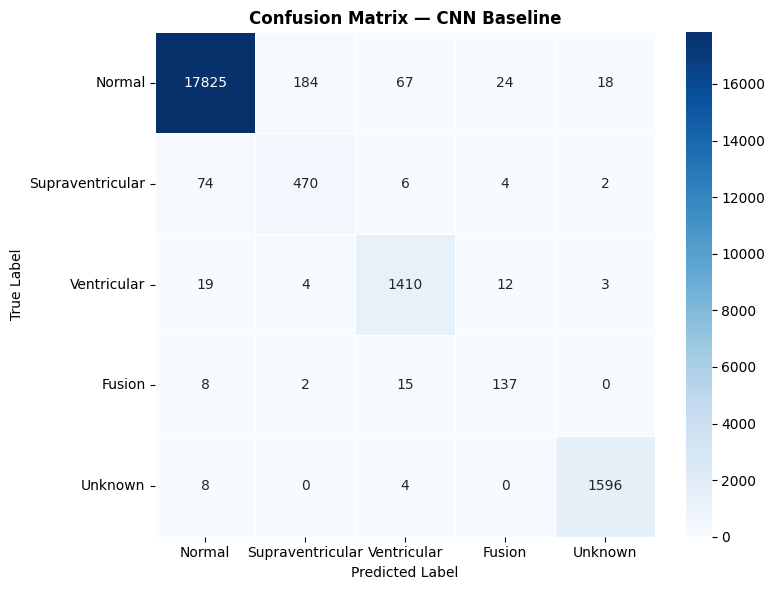

In [22]:
y_pred_cnn = evaluate_model(cnn_model, X_test, y_test, 'CNN Baseline', 'Blues')

# **Model 2 — Improved DenseNet with Transition Layers**

In [23]:
# ──────────────────────────────────────────────────────────────
# MODEL 2: IMPROVED DENSENET
#
# KEY IMPROVEMENT over original notebook:
# After each dense_block → transition_layer compresses channels.
#
# Without transition: channels after 3 blocks = 1 + 32 + 32 + 64 + 64 + 128 + 128 = ~450
# With transition:    channels after 3 blocks = 32 → 64 → 128 (controlled)
#
# This is the DenseNet-BC (Bottleneck + Compression) design from:
# Huang et al., 'Densely Connected Convolutional Networks', CVPR 2017.
# Used here for 1D ECG signals.
# ──────────────────────────────────────────────────────────────
def build_densenet_improved():
    inp = Input(shape=(187, 1), name='ecg_input')

    # ── Stage 1 ────────────────────────────────────────────────
    # Initial conv to establish 32-channel feature space
    x = Conv1D(32, 5, padding='same', activation='relu')(inp)
    x = BatchNormalization()(x)
    # Dense block: each conv sees ALL previous outputs
    x = dense_block(x, 32)
    # Transition: compress back to 32 channels and halve time resolution
    # Without this, the concatenated output would be ~96 channels here
    x = transition_layer(x, out_filters=32)

    # ── Stage 2 ────────────────────────────────────────────────
    x = Conv1D(64, 3, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    x = dense_block(x, 64)
    x = transition_layer(x, out_filters=64)  # Compresses ~192 → 64

    # ── Stage 3 ────────────────────────────────────────────────
    x = Conv1D(128, 3, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    x = dense_block(x, 128)
    x = transition_layer(x, out_filters=128)  # Compresses ~384 → 128

    # Global average pooling collapses the temporal dimension
    # to a single 128-dimensional feature vector per beat
    x = GlobalAveragePooling1D()(x)

    # Dense classification head with L2 regularisation + dropout
    x = Dense(128, activation='relu',
              kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = Dropout(0.4)(x)
    x = Dense(64, activation='relu',
              kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = Dropout(0.3)(x)
    out = Dense(NUM_CLASSES, activation='softmax')(x)

    return Model(inp, out, name='DenseNet_Improved')


densenet_model = build_densenet_improved()
densenet_model.compile(
    # clipnorm=1.0 clips gradients to unit norm — prevents exploding
    # gradients that can destabilise DenseNet training due to the
    # many concatenation paths creating very long backprop chains.
    optimizer=Adam(learning_rate=0.0005, clipnorm=1.0),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
densenet_model.summary()

Model: "DenseNet_Improved"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ecg_input           │ (None, 187, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 187, 32)   │        192 │ ecg_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 187, 32)   │        128 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 187, 32)   │      3,104 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 187, 32)   │        128 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_3 │ (None, 187, 32)   │          0 │ batch_normalizat… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 187, 64)   │          0 │ batch_normalizat… │
│ (Concatenate)       │                   │            │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 187, 32)   │      6,176 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 187, 32)   │        128 │ conv1d_5[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_4 │ (None, 187, 32)   │          0 │ batch_normalizat… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 187, 96)   │          0 │ batch_normalizat… │
│ (Concatenate)       │                   │            │ spatial_dropout1… │
│                     │                   │            │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 187, 32)   │      3,104 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 187, 32)   │        128 │ conv1d_6[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 93, 32)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 93, 64)    │      6,208 │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 93, 64)    │        256 │ conv1d_7[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 93, 64)    │     12,352 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 93, 64)    │        256 │ conv1d_8[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 318,501 (1.21 MB)

 Trainable params: 316,709 (1.21 MB)

 Non-trainable params: 1,792 (7.00 KB)

In [24]:
callbacks_dense = [
    EarlyStopping(monitor='val_accuracy', patience=10,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_accuracy', factor=0.5,
                      patience=4, min_lr=1e-7, verbose=1),
    ModelCheckpoint('/kaggle/working/best_densenet.keras',
                    monitor='val_accuracy', save_best_only=True, verbose=0)
]

history_dense = densenet_model.fit(
    X_train, y_train,
    epochs=60, batch_size=128,
    validation_split=0.15,
    class_weight=class_weights,
    callbacks=callbacks_dense,
    verbose=1
)
print('Improved DenseNet training complete!')

Epoch 1/60


2026-11-12 12:07:27.787192: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-12 12:07:28.011478: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-12 12:07:29.785385: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng3{k11=2} for conv %cudnn-conv.33 = (f32[96,32,1,1]{3,2,1,0}, u8[0]{0}) custom-call(f32[96,128,1,187]{3,2,1,0} %bitcast.38968, f32[32,128,1,187]{3,2,1,0} %bitcast.38975), window={size=1x187}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convForward", metadata={op_type="Conv2DBackpropFilter" op_name="gradient_tape/DenseNet_Improved_1/conv1d_6_1/convolution/Conv2DBackpropFilter" source_file="/usr/local/lib/pyt

629/629 ━━━━━━━━━━━━━━━━━━━━ 53s 43ms/step - accuracy: 0.5688 - loss: 0.9174 - val_accuracy: 0.7340 - val_loss: 0.7801 - learning_rate: 5.0000e-04
Epoch 2/60
629/629 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.8910 - loss: 0.3270 - val_accuracy: 0.9475 - val_loss: 0.2044 - learning_rate: 5.0000e-04
Epoch 3/60
629/629 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9224 - loss: 0.2539 - val_accuracy: 0.9556 - val_loss: 0.1884 - learning_rate: 5.0000e-04
Epoch 4/60
629/629 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9301 - loss: 0.2115 - val_accuracy: 0.9382 - val_loss: 0.2317 - learning_rate: 5.0000e-04
Epoch 5/60
629/629 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9326 - loss: 0.1898 - val_accuracy: 0.9370 - val_loss: 0.2369 - learning_rate: 5.0000e-04
Epoch 6/60
629/629 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.9394 - loss: 0.1770 - val_accuracy: 0.9613 - val_loss: 0.1571 - learning_rate: 5.0000e-04
Epoch 7/60
629/629 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.


=== DenseNet (Improved) ===
                  precision    recall  f1-score   support

          Normal     0.9937    0.9895    0.9916     18118
Supraventricular     0.8117    0.8453    0.8282       556
     Ventricular     0.9480    0.9689    0.9583      1448
          Fusion     0.7528    0.8272    0.7882       162
         Unknown     0.9882    0.9919    0.9901      1608

        accuracy                         0.9834     21892
       macro avg     0.8989    0.9246    0.9113     21892
    weighted avg     0.9839    0.9834    0.9836     21892



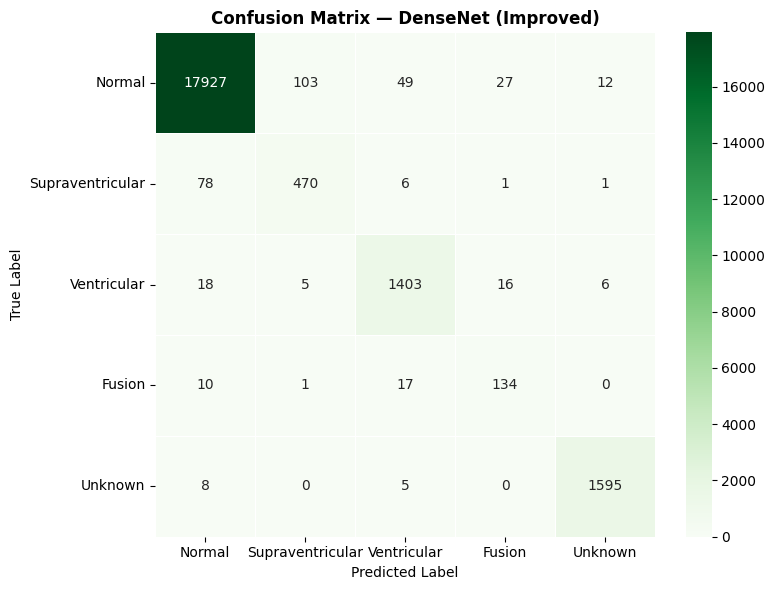

In [25]:
y_pred_dense = evaluate_model(densenet_model, X_test, y_test,
                               'DenseNet (Improved)', 'Greens')

# **Model 3 — DenseNet + Multi-Scale Multi-Head Attention **

In [26]:
# ──────────────────────────────────────────────────────────────
# MODEL 3: DenseNet + MULTI-SCALE ATTENTION
#
# Design idea (in our results this did not beat the plain DenseNet):
#
# PROBLEM with single late attention (original notebook):
#   Attention placed after all 3 dense blocks operates on 23 timesteps.
#   23 timesteps = ~184ms at 125Hz — not enough resolution to distinguish
#   fine morphology differences.
#
# SOLUTION — two attention blocks at different temporal scales:
#   - attn_1 (mid-scale): after Stage 2, operates on ~46 timesteps (~368ms)
#     → captures QRS-to-T-wave relationships
#   - attn_2 (fine-scale): after Stage 3, operates on ~23 timesteps (~184ms)
#     → captures fine morphology within the QRS complex
#
# This multi-scale design is inspired by:
# Dosovitskiy et al., 'An Image is Worth 16x16 Words' (ViT, 2020)
# adapted for 1D temporal signals.
# ──────────────────────────────────────────────────────────────
def build_proposed_model():
    inp = Input(shape=(187, 1), name='ecg_input')

    # ── Stage 1: Low-level feature extraction ─────────────────
    # Broad kernel (5) captures slow waveform components (ST segment and T-wave)
    x = Conv1D(32, 5, padding='same', activation='relu')(inp)
    x = BatchNormalization()(x)
    x = dense_block(x, 32)
    x = transition_layer(x, out_filters=32)   # 187 → 93 timesteps

    # ── Stage 2: Mid-level feature extraction ─────────────────
    x = Conv1D(64, 3, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    x = dense_block(x, 64)
    x = transition_layer(x, out_filters=64)   # 93 → 46 timesteps

    # ── ATTENTION BLOCK 1: Mid-scale (46 timesteps ≈ 128ms) ───
    # At this resolution, the model can learn which temporal segments
    # (PR interval, QRS onset, ST segment) are most discriminative
    # for each arrhythmia class.
    # 4 heads × key_dim 16 = 64 attention dimensions
    x = attention_block(x, num_heads=4, key_dim=16, name_prefix='attn1')

    # ── Stage 3: High-level feature extraction ────────────────
    x = Conv1D(128, 3, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    x = dense_block(x, 128)
    x = transition_layer(x, out_filters=128)  # 46 → 23 timesteps

    # ── ATTENTION BLOCK 2: Fine-scale (23 timesteps ≈ 64ms) ───
    # At this compressed resolution, attention learns which of the
    # high-level features (e.g., QRS notch, ST elevation) are
    # diagnostically critical for the final classification.
    # 8 heads for richer attention diversity at the decision layer.
    x = attention_block(x, num_heads=8, key_dim=16, name_prefix='attn2')

    # Global average pooling → 128-dim beat representation
    x = GlobalAveragePooling1D()(x)

    # ── Classification head ───────────────────────────────────
    x = Dense(128, activation='relu',
              kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = Dropout(0.4)(x)
    x = Dense(64, activation='relu',
              kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = Dropout(0.3)(x)
    out = Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)

    return Model(inp, out, name='DenseNet_MultiScale_Attention')


proposed_model = build_proposed_model()
proposed_model.compile(
    optimizer=Adam(learning_rate=0.0005, clipnorm=1.0),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
proposed_model.summary()
print(f'\nTotal trainable parameters: {proposed_model.count_params():,}')

Model: "DenseNet_MultiScale_Attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ecg_input           │ (None, 187, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_15 (Conv1D)  │ (None, 187, 32)   │        192 │ ecg_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 187, 32)   │        128 │ conv1d_15[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_16 (Conv1D)  │ (None, 187, 32)   │      3,104 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 187, 32)   │        128 │ conv1d_16[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_9 │ (None, 187, 32)   │          0 │ batch_normalizat… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 187, 64)   │          0 │ batch_normalizat… │
│ (Concatenate)       │                   │            │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_17 (Conv1D)  │ (None, 187, 32)   │      6,176 │ concatenate_6[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 187, 32)   │        128 │ conv1d_17[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 187, 32)   │          0 │ batch_normalizat… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 187, 96)   │          0 │ batch_normalizat… │
│ (Concatenate)       │                   │            │ spatial_dropout1… │
│                     │                   │            │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_18 (Conv1D)  │ (None, 187, 32)   │      3,104 │ concatenate_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 187, 32)   │        128 │ conv1d_18[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_6     │ (None, 93, 32)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_19 (Conv1D)  │ (None, 93, 64)    │      6,208 │ max_pooling1d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 93, 64)    │        256 │ conv1d_19[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_20 (Conv1D)  │ (None, 93, 64)    │     12,352 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 93, 64)    │        256 │ conv1d_20[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 442,917 (1.69 MB)

 Trainable params: 441,125 (1.68 MB)

 Non-trainable params: 1,792 (7.00 KB)


Total trainable parameters: 442,917


In [27]:
callbacks_proposed = [
    EarlyStopping(monitor='val_accuracy', patience=12,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_accuracy', factor=0.5,
                      patience=4, min_lr=1e-7, verbose=1),
    ModelCheckpoint('/kaggle/working/best_proposed.keras',
                    monitor='val_accuracy', save_best_only=True, verbose=0)
]

history_proposed = proposed_model.fit(
    X_train, y_train,
    epochs=80,           # More epochs allowed — early stopping will decide when to stop
    batch_size=128,
    validation_split=0.15,
    class_weight=class_weights,
    callbacks=callbacks_proposed,
    verbose=1
)
print('Proposed model training complete!')

Epoch 1/80
629/629 ━━━━━━━━━━━━━━━━━━━━ 65s 55ms/step - accuracy: 0.5714 - loss: 1.0005 - val_accuracy: 0.7993 - val_loss: 0.6588 - learning_rate: 5.0000e-04
Epoch 2/80
629/629 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.8958 - loss: 0.3397 - val_accuracy: 0.7446 - val_loss: 0.7495 - learning_rate: 5.0000e-04
Epoch 3/80
629/629 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.9223 - loss: 0.2735 - val_accuracy: 0.8951 - val_loss: 0.3196 - learning_rate: 5.0000e-04
Epoch 4/80
629/629 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.9313 - loss: 0.2267 - val_accuracy: 0.9511 - val_loss: 0.2020 - learning_rate: 5.0000e-04
Epoch 5/80
629/629 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.9377 - loss: 0.2093 - val_accuracy: 0.9511 - val_loss: 0.2077 - learning_rate: 5.0000e-04
Epoch 6/80
629/629 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.9417 - loss: 0.1878 - val_accuracy: 0.9468 - val_loss: 0.2256 - learning_rate: 5.0000e-04
Epoch 7/80
629/629 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/ste


=== DenseNet + Multi-Scale Attention  ===
                  precision    recall  f1-score   support

          Normal     0.9933    0.9919    0.9926     18118
Supraventricular     0.8401    0.8219    0.8309       556
     Ventricular     0.9528    0.9627    0.9577      1448
          Fusion     0.7268    0.8210    0.7710       162
         Unknown     0.9932    0.9944    0.9938      1608

        accuracy                         0.9846     21892
       macro avg     0.9012    0.9184    0.9092     21892
    weighted avg     0.9848    0.9846    0.9846     21892



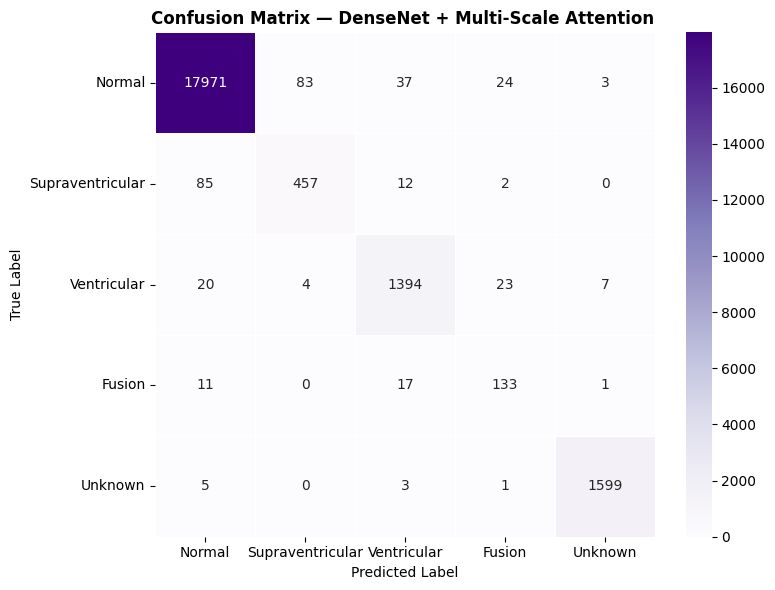

In [28]:
y_pred_proposed = evaluate_model(proposed_model, X_test, y_test,
                                  'DenseNet + Multi-Scale Attention ', 'Purples')

# **Training Curves — Overfitting Diagnostic**

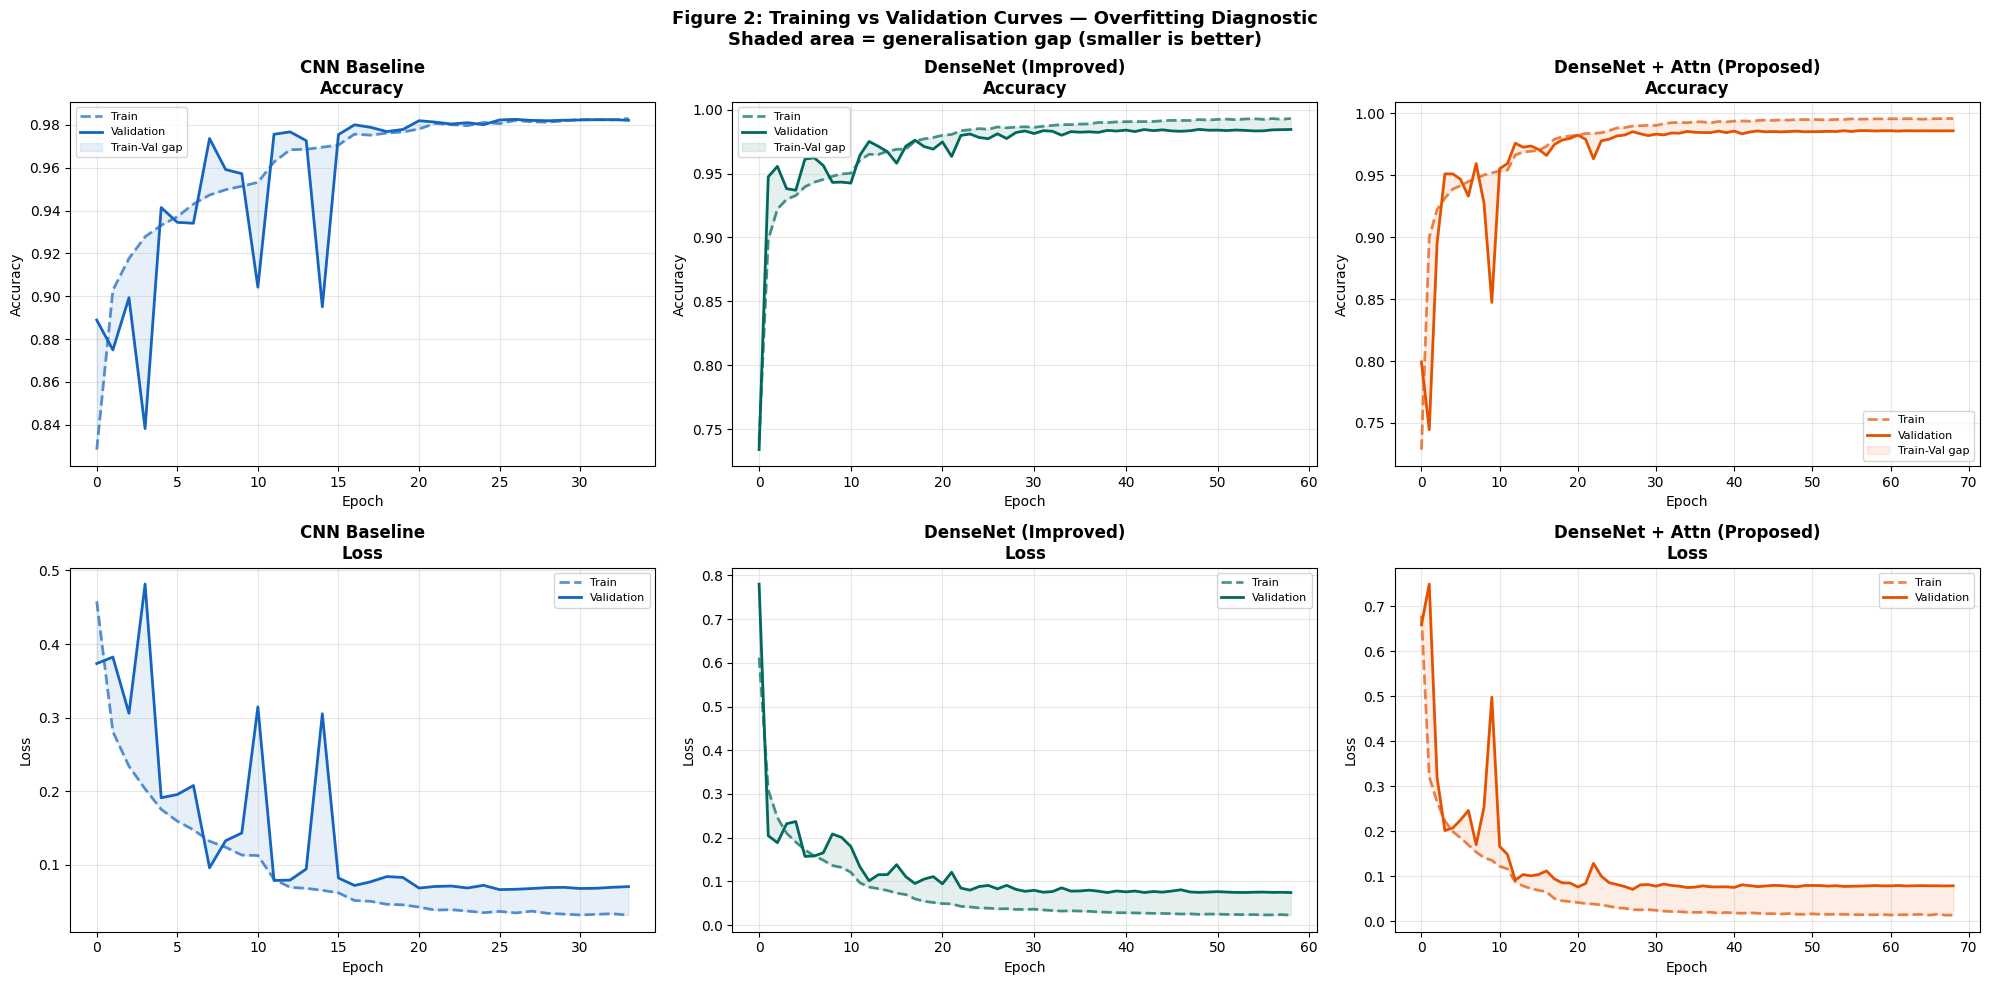

In [29]:
# ──────────────────────────────────────────────────────────────
# TRAINING CURVES — KEY DIAGNOSTIC FOR OVERFITTING
# The gap between train and val curves is the overfitting signal:
#   - Small gap: model generalises well
#   - Large gap: model memorises training data
# Both accuracy AND loss are plotted — val_accuracy alone can be
# misleading on imbalanced datasets (Normal class dominates accuracy).
# ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(20, 10))

configs = [
    ('CNN Baseline',              history_cnn,      '#1565C0'),
    ('DenseNet (Improved)',       history_dense,    '#00695C'),
    ('DenseNet + Attn (Proposed)',history_proposed, '#E65100'),
]

for col, (label, hist, color) in enumerate(configs):
    # Accuracy subplot
    ax_acc = axes[0][col]
    ax_acc.plot(hist.history['accuracy'],     color=color, linewidth=2,
                label='Train', linestyle='--', alpha=0.7)
    ax_acc.plot(hist.history['val_accuracy'], color=color, linewidth=2,
                label='Validation')
    # Shade the gap between train and val — larger gap = more overfitting
    ax_acc.fill_between(
        range(len(hist.history['accuracy'])),
        hist.history['accuracy'],
        hist.history['val_accuracy'],
        alpha=0.10, color=color, label='Train-Val gap'
    )
    ax_acc.set_title(f'{label}\nAccuracy', fontweight='bold')
    ax_acc.set_xlabel('Epoch'); ax_acc.set_ylabel('Accuracy')
    ax_acc.legend(fontsize=8); ax_acc.grid(alpha=0.3)

    # Loss subplot
    ax_loss = axes[1][col]
    ax_loss.plot(hist.history['loss'],     color=color, linewidth=2,
                 label='Train', linestyle='--', alpha=0.7)
    ax_loss.plot(hist.history['val_loss'], color=color, linewidth=2,
                 label='Validation')
    ax_loss.fill_between(
        range(len(hist.history['loss'])),
        hist.history['loss'],
        hist.history['val_loss'],
        alpha=0.10, color=color
    )
    ax_loss.set_title(f'{label}\nLoss', fontweight='bold')
    ax_loss.set_xlabel('Epoch'); ax_loss.set_ylabel('Loss')
    ax_loss.legend(fontsize=8); ax_loss.grid(alpha=0.3)

plt.suptitle(
    'Figure 2: Training vs Validation Curves — Overfitting Diagnostic\n'
    'Shaded area = generalisation gap (smaller is better)',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig('fig2_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

# **Model Comparison Table**

In [30]:
# ──────────────────────────────────────────────────────────────
# MODEL COMPARISON
# Macro F1 is the primary metric for reporting on imbalanced
# datasets — it averages F1 across all classes equally, so good
# performance on minority classes is not hidden by Normal class dominance.
# ──────────────────────────────────────────────────────────────
scores = {
    'CNN Baseline':         get_scores(y_test, y_pred_cnn),
    'DenseNet (Improved)':  get_scores(y_test, y_pred_dense),
    'Proposed (DenseNet+MSMHA)': get_scores(y_test, y_pred_proposed),
}

df_scores = pd.DataFrame(scores).T
print('=' * 80)
print('   FINAL MODEL COMPARISON')
print('=' * 80)
print(df_scores.to_string())
print('=' * 80)
print(f"\n Best Accuracy  → {df_scores['Accuracy'].idxmax()}  ({df_scores['Accuracy'].max():.4f})")
print(f" Best Macro F1  → {df_scores['Macro F1'].idxmax()}  ({df_scores['Macro F1'].max():.4f})")
print(f" Best Ventric   → {df_scores['Ventric F1'].idxmax()}  ({df_scores['Ventric F1'].max():.4f})")
print(f" Best Fusion    → {df_scores['Fusion F1'].idxmax()}  ({df_scores['Fusion F1'].max():.4f})")

# ── Parameter count comparison  ───────
print('\n=== PARAMETER COUNT ===')
for name, model in [('CNN Baseline', cnn_model),
                     ('DenseNet (Improved)', densenet_model),
                     ('Proposed', proposed_model)]:
    print(f'  {name:35s}: {model.count_params():>10,} parameters')

   FINAL MODEL COMPARISON
                           Accuracy  Normal F1  SVT F1  Ventric F1  Fusion F1  Unknown F1  Macro F1
CNN Baseline                 0.9793     0.9888  0.7730      0.9559     0.8083      0.9892    0.9030
DenseNet (Improved)          0.9834     0.9916  0.8282      0.9583     0.7882      0.9901    0.9113
Proposed (DenseNet+MSMHA)    0.9846     0.9926  0.8309      0.9577     0.7710      0.9938    0.9092

 Best Accuracy  → Proposed (DenseNet+MSMHA)  (0.9846)
 Best Macro F1  → DenseNet (Improved)  (0.9113)
 Best Ventric   → DenseNet (Improved)  (0.9583)
 Best Fusion    → CNN Baseline  (0.8083)

=== PARAMETER COUNT ===
  CNN Baseline                       :    224,901 parameters
  DenseNet (Improved)                :    318,501 parameters
  Proposed                           :    442,917 parameters


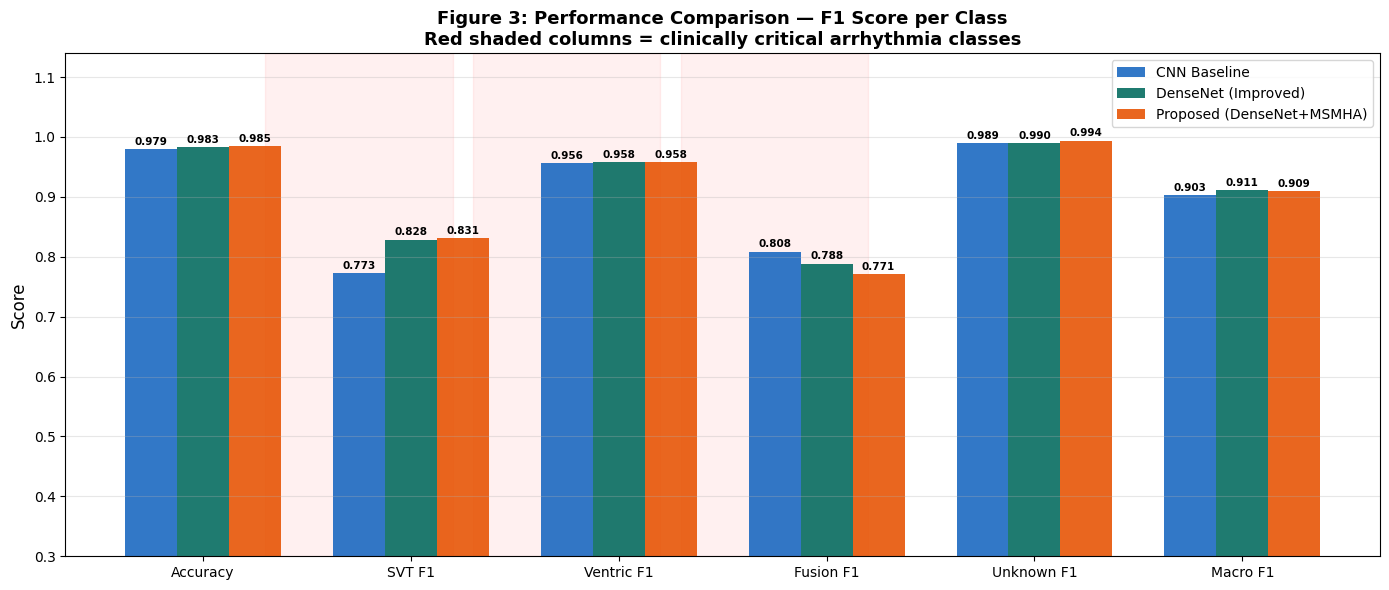

In [31]:
# ──────────────────────────────────────────────────────────────
# GROUPED BAR CHART — Figure 3
# Shows per-class F1 scores for all three models side-by-side.
# Clinically dangerous classes (SVT, Ventricular, Fusion) are
# annotated with a red background to draw reviewer attention.
# ──────────────────────────────────────────────────────────────
metrics  = ['Accuracy', 'SVT F1', 'Ventric F1', 'Fusion F1', 'Unknown F1', 'Macro F1']
x        = np.arange(len(metrics))
width    = 0.25
bar_cols = ['#1565C0', '#00695C', '#E65100']

fig, ax = plt.subplots(figsize=(14, 6))

# Shade clinically critical columns (SVT, Ventric, Fusion)
for xi, label in zip(x, metrics):
    if label in ['SVT F1', 'Ventric F1', 'Fusion F1']:
        ax.axvspan(xi - 0.45, xi + 0.45, alpha=0.06, color='red')

for i, (model_name, color) in enumerate(zip(scores.keys(), bar_cols)):
    vals = [scores[model_name][m] for m in metrics]
    bars = ax.bar(x + i*width, vals, width, label=model_name,
                  color=color, alpha=0.88)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.004,
                f'{val:.3f}', ha='center', va='bottom',
                fontsize=7.5, fontweight='bold')

ax.set_xticks(x + width)
ax.set_xticklabels(metrics, fontsize=10)
ax.set_ylim(0.3, 1.14)
ax.set_ylabel('Score', fontsize=12)
ax.set_title(
    'Figure 3: Performance Comparison — F1 Score per Class\n'
    'Red shaded columns = clinically critical arrhythmia classes',
    fontsize=13, fontweight='bold'
)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('fig3_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# **Healthcare Metrics — Sensitivity, Specificity, PPV**

In [32]:
# ──────────────────────────────────────────────────────────────
# CLINICAL EVALUATION METRICS
#
# For imbalanced biomedical data, accuracy alone is insufficient.
# Reviewers expect these three metrics:
#
# Sensitivity (Recall): TP / (TP + FN)
#   How many dangerous beats did we CATCH?
#   A missed Ventricular beat (FN) can lead to sudden cardiac death.
#   Target: >0.90 for Ventricular and SVT classes.
#
# Specificity: TN / (TN + FP)
#   How often do we avoid false alarms?
#   False positives → unnecessary interventions, patient anxiety.
#   Target: >0.95 for Normal class.
#
# PPV (Precision): TP / (TP + FP)
#   When we flag a dangerous beat, how often are we right?
#   Low PPV → alarm fatigue in clinical settings.
# ──────────────────────────────────────────────────────────────

def healthcare_metrics(y_true, y_pred, model_name):
    print(f'\n{"="*72}')
    print(f'  {model_name}')
    print(f'{"="*72}')
    print(f'{"Class":20s}  {"Sensitivity":>12s}  {"Specificity":>12s}  '
          f'{"PPV":>8s}  {"Status"}')
    print('-' * 72)

    # Clinical risk level per class
    risk  = {0:'Low', 1:'HIGH', 2:'HIGH', 3:'MEDIUM', 4:'Low'}
    # Threshold for "needs improvement" flag
    thres = {0: 0.95,   1: 0.85,   2: 0.90,   3: 0.80,   4: 0.75}

    for i, name in enumerate(CLASS_NAMES):
        tp   = np.sum((y_true == i) & (y_pred == i))
        fn   = np.sum((y_true == i) & (y_pred != i))
        tn   = np.sum((y_true != i) & (y_pred != i))
        fp   = np.sum((y_true != i) & (y_pred == i))
        sens = tp / (tp + fn + 1e-8)
        spec = tn / (tn + fp + 1e-8)
        ppv  = tp / (tp + fp + 1e-8)
        flag = ' ← NEEDS IMPROVEMENT' if sens < thres[i] else ' ✓'
        print(f'{name:20s}  {sens:12.4f}  {spec:12.4f}  {ppv:8.4f}  '
              f'{risk[i]}{flag}')


healthcare_metrics(y_test, y_pred_cnn,      'CNN BASELINE')
healthcare_metrics(y_test, y_pred_dense,    'DENSENET (IMPROVED)')
healthcare_metrics(y_test, y_pred_proposed, 'DenseNet + Multi-Scale Attention')

# ── Clinical score comparison ──────────────────────────────────
print('\n=== CLINICAL PRIORITY SCORE (higher is better) ===')
c_scores = {
    'CNN Baseline':   clinical_score(y_test, y_pred_cnn),
    'DenseNet':       clinical_score(y_test, y_pred_dense),
    'Proposed':       clinical_score(y_test, y_pred_proposed),
}
best_name = max(c_scores, key=c_scores.get)
for name, sc in c_scores.items():
    marker = ' ← BEST CLINICAL MODEL' if name == best_name else ''
    print(f'  {name:35s}: {sc:.4f}{marker}')


  CNN BASELINE
Class                  Sensitivity   Specificity       PPV  Status
------------------------------------------------------------------------
Normal                      0.9838        0.9711    0.9939  Low ✓
Supraventricular            0.8453        0.9911    0.7121  HIGH ← NEEDS IMPROVEMENT
Ventricular                 0.9738        0.9955    0.9387  HIGH ✓
Fusion                      0.8457        0.9982    0.7740  MEDIUM ✓
Unknown                     0.9925        0.9989    0.9858  Low ✓

  DENSENET (IMPROVED)
Class                  Sensitivity   Specificity       PPV  Status
------------------------------------------------------------------------
Normal                      0.9895        0.9698    0.9937  Low ✓
Supraventricular            0.8453        0.9949    0.8117  HIGH ← NEEDS IMPROVEMENT
Ventricular                 0.9689        0.9962    0.9480  HIGH ✓
Fusion                      0.8272        0.9980    0.7528  MEDIUM ✓
Unknown                     0.9919       

## 🎯 Select Best Model for Grad-CAM

In [33]:
# ──────────────────────────────────────────────────────────────
# AUTO-SELECT BEST MODEL
# Use clinical_score (not accuracy) as the selection criterion
# — this ensures we pick the model that performs best on
# dangerous classes, which is what matters clinically.
# ──────────────────────────────────────────────────────────────
model_map = {
    'CNN Baseline': (cnn_model,      y_pred_cnn),
    'DenseNet':     (densenet_model, y_pred_dense),
    'Proposed':     (proposed_model, y_pred_proposed),
}
best_model_name = max(c_scores, key=c_scores.get)
best_model, best_preds = model_map[best_model_name]
print(f'Selected for Grad-CAM: {best_model_name} (clinical score: {c_scores[best_model_name]:.4f})')

Selected for Grad-CAM: CNN Baseline (clinical score: 0.9163)


# **Grad-CAM: attention per ECG region**
Mean Grad-CAM attention per region, averaged over correctly classified test beats of each class. Region boundaries are approximate (see the next cell). This is a descriptive summary of what the model attends to, not a clinical validation.


In [34]:
# ──────────────────────────────────────────────────────────────
# GRAD-CAM FOR 1D ECG SIGNALS
# Gradient-weighted Class Activation Mapping (Selvaraju et al., 2017),
# adapted to 1D: gradients of the target class score w.r.t. the last Conv1D
# output are pooled per channel, used to weight the activation maps, passed
# through ReLU, normalised and interpolated back to 187 timesteps.
#
# REGION BOUNDARIES
# Facts used: the Kaggle heartbeat data is resampled to 125 Hz (1 sample = 8 ms),
# every beat starts at its R-peak and is zero-padded to 187 samples.
# So the window starts inside the QRS and contains NO P-wave (that belongs to
# the previous beat). The class-mean beats show the QRS in roughly the first 10-12
# samples and a T-wave bump around samples 25-65.
# These boundaries are APPROXIMATE and only a convention for summarising attention.
# They are not clinical annotations. Wide Ventricular QRS complexes spill into the
# next region.
# ──────────────────────────────────────────────────────────────
ECG_REGIONS = {
    'QRS':        (0,  12),
    'ST-segment': (12, 28),
    'T-wave':     (28, 65),
    'Late beat':  (65, 187),   # cut at the end of the beat, zero padding excluded
}
REGION_BG = {
    'QRS':        '#FCE4EC',
    'ST-segment': '#FFF9C4',
    'T-wave':     '#E8F5E9',
}


def get_last_conv_layer(model):
    """Find the name of the last Conv1D layer in the model."""
    last = None
    for layer in model.layers:
        if isinstance(layer, tf.keras.layers.Conv1D):
            last = layer.name
    if last is None:
        raise ValueError('No Conv1D layer found in model')
    return last


def grad_cam_1d(model, signal, class_idx):
    """
    Compute Grad-CAM heatmap for a single ECG signal.

    Args:
        model     : trained Keras model
        signal    : single beat, shape (187, 1)
        class_idx : target class index (0-4)
    Returns:
        heatmap_187 : normalised importance at each of 187 timesteps
        last_conv   : name of the conv layer used
    """
    last_conv = get_last_conv_layer(model)

    # Build a model that outputs [conv_activations, class_predictions]
    grad_model = tf.keras.models.Model(
        inputs=model.input,
        outputs=[model.get_layer(last_conv).output, model.output]
    )

    sig_in = tf.cast(tf.expand_dims(signal, 0), tf.float32)

    # GradientTape records all operations for automatic differentiation
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(sig_in, training=False)
        # Scalar loss = the predicted probability for target class
        loss = preds[:, class_idx]

    # Gradient of target class score w.r.t. each conv feature map
    grads = tape.gradient(loss, conv_out)          # shape: (1, T, C)

    # Global average pool gradients across temporal axis → importance per channel
    pooled = tf.reduce_mean(grads, axis=(0, 1))    # shape: (C,)

    # Weighted sum of activation maps
    heatmap = tf.reduce_sum(conv_out[0] * pooled, axis=-1)  # shape: (T,)

    # ReLU: only positive influences on the target class matter
    heatmap = tf.nn.relu(heatmap)

    # Normalise to [0, 1]
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    # Upsample from conv output size back to 187 using linear interpolation
    h = heatmap.numpy()
    heatmap_187 = np.interp(
        np.linspace(0, len(h)-1, 187),
        np.arange(len(h)), h
    )
    return heatmap_187, last_conv


def beat_length(signal):
    """Index after the last non-zero sample (the rest is zero padding)."""
    nz = np.nonzero(np.asarray(signal).flatten())[0]
    return int(nz.max()) + 1 if len(nz) else 187


def region_importance(hmap_187, signal=None):
    """
    Mean Grad-CAM value inside each region, normalised to sum to 100%.
    Zero-padded samples are excluded when the signal is given.
    Returns all zeros if the heatmap is empty (ReLU removed everything).
    """
    end_all = beat_length(signal) if signal is not None else 187
    raw = {}
    for region, (start, end) in ECG_REGIONS.items():
        end = min(end, end_all)
        raw[region] = float(np.mean(hmap_187[start:end])) if end > start else 0.0
    total = sum(raw.values())
    if total <= 1e-8:
        return {k: 0.0 for k in raw}
    return {k: round(v / total * 100, 1) for k, v in raw.items()}


print('Grad-CAM ready!')
print('Last conv layer:', get_last_conv_layer(best_model))


Grad-CAM ready!
Last conv layer: conv1d_2



=== MEAN GRAD-CAM ATTENTION PER REGION (%) ===
Class                         QRS   ST-segment       T-wave    Late beat   beats used
-------------------------------------------------------------------------------------
Normal                      49.7%        11.9%        14.3%        24.1%   175/200
Supraventricular             9.8%        27.4%        30.3%        32.4%   151/200
Ventricular                 30.8%        11.6%        23.9%        22.6%   172/200
Fusion                       5.2%        52.3%        24.2%        16.7%   134/137
Unknown                     13.6%        33.2%        16.0%        17.2%   185/200


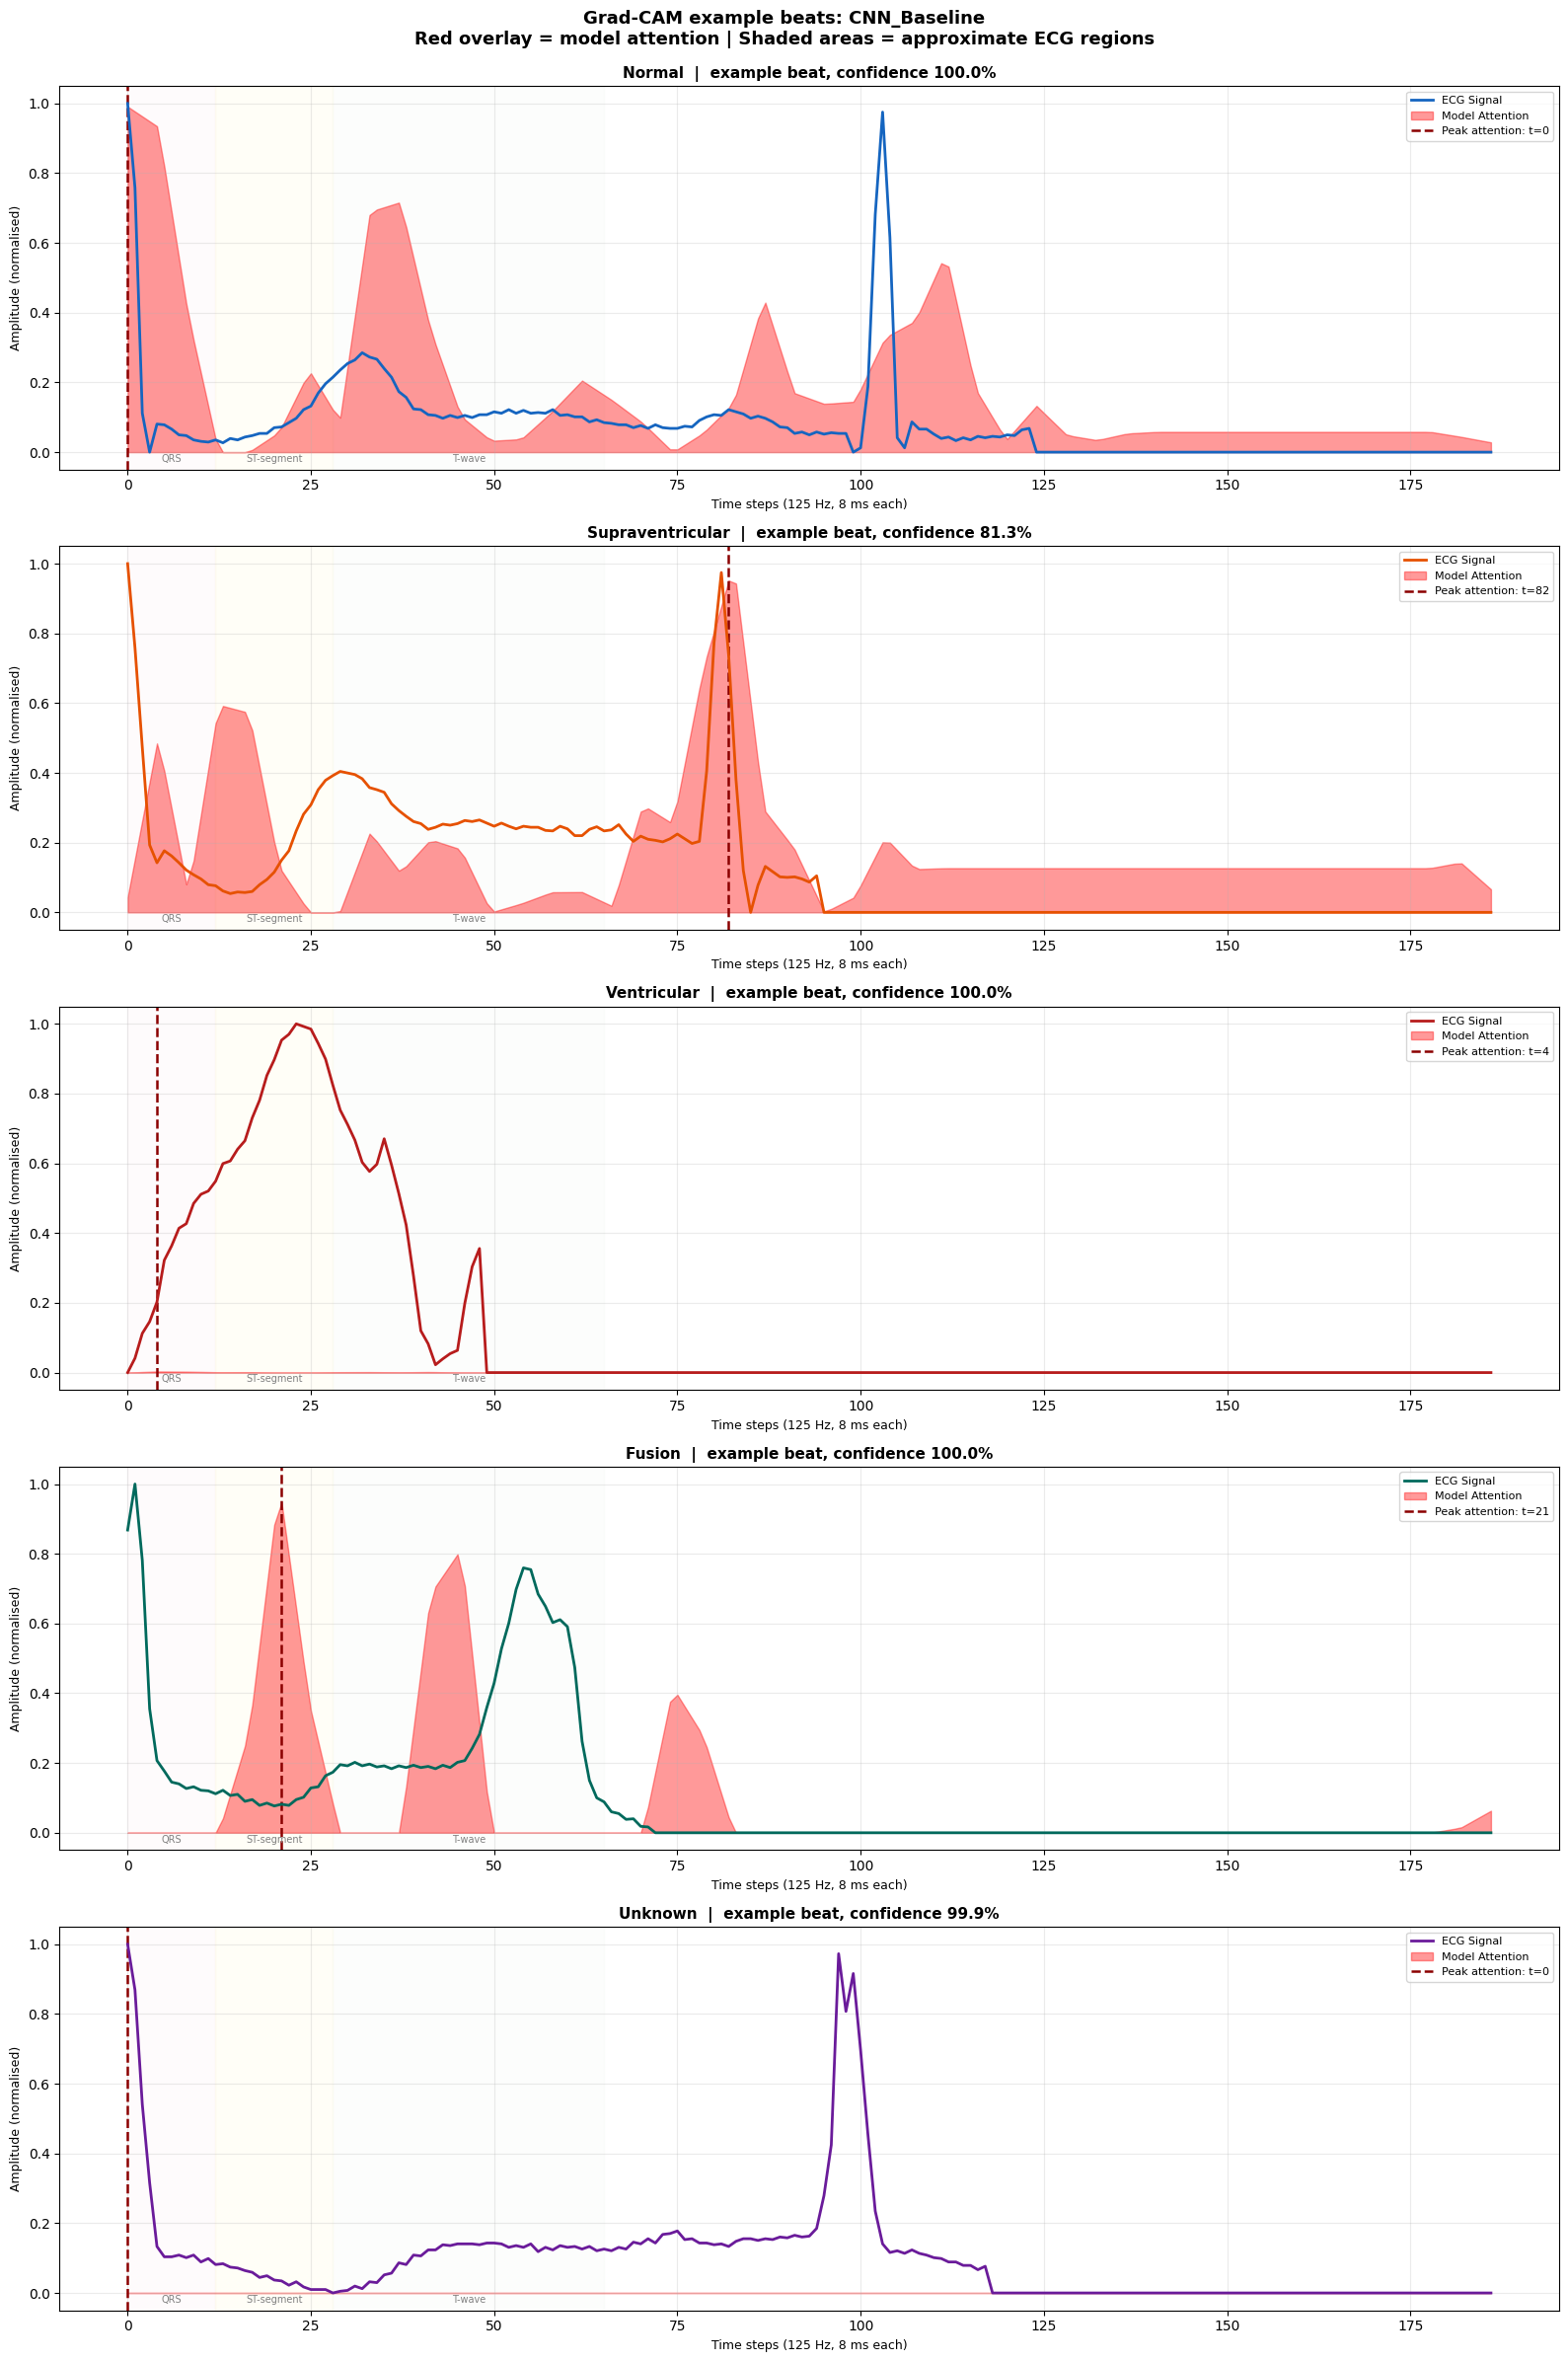


Grad-CAM complete. "beats used" = beats whose heatmap was not empty / correct beats found.


In [35]:
# ──────────────────────────────────────────────────────────────
# GRAD-CAM: one example beat per class, plus region attention averaged over
# up to N_BEATS correctly classified test beats per class.
# ──────────────────────────────────────────────────────────────
N_BEATS = 200
fig, axes = plt.subplots(5, 1, figsize=(16, 24))
fig.suptitle(
    f'Grad-CAM example beats: {best_model.name}\n'
    'Red overlay = model attention | Shaded areas = approximate ECG regions',
    fontsize=13, fontweight='bold', y=0.995
)

print('\n=== MEAN GRAD-CAM ATTENTION PER REGION (%) ===')
header = f'{"Class":20s}' + ''.join(f'  {r:>11s}' for r in ECG_REGIONS.keys()) + '   beats used'
print(header)
print('-' * len(header))

region_table = {}   # class name -> mean % per region
n_used = {}         # class name -> (beats with non-empty heatmap, correct beats found)

for class_idx in range(NUM_CLASSES):
    name = CLASS_NAMES[class_idx]
    idxs = np.where(y_test == class_idx)[0][:N_BEATS * 3]
    preds = np.argmax(best_model.predict(X_test[idxs], verbose=0), axis=1)
    correct = idxs[preds == class_idx][:N_BEATS]

    if len(correct) == 0:
        axes[class_idx].set_title(f'{name}: no correctly classified beat found')
        continue

    rims = []
    for idx in correct:
        hmap_i, _ = grad_cam_1d(best_model, X_test[idx], class_idx)
        if hmap_i.max() > 0:
            rims.append(region_importance(hmap_i, X_test[idx]))
    n_used[name] = (len(rims), len(correct))

    if rims:
        mean_rim = {r: round(float(np.mean([d[r] for d in rims])), 1) for r in ECG_REGIONS}
    else:
        mean_rim = {r: float('nan') for r in ECG_REGIONS}
    region_table[name] = mean_rim

    print(f'{name:20s}' + ''.join(f'  {mean_rim[r]:>10.1f}%' for r in ECG_REGIONS)
          + f'   {len(rims)}/{len(correct)}')

    # Example beat for the figure: first correctly classified beat
    signal = X_test[correct[0]]
    hmap, _ = grad_cam_1d(best_model, signal, class_idx)
    sig  = signal.flatten()
    smin = sig.min()
    srng = sig.max() - smin + 1e-8
    ax   = axes[class_idx]

    for region, (start, end) in ECG_REGIONS.items():
        if region in REGION_BG:
            ax.axvspan(start, end, alpha=0.12, color=REGION_BG[region])
            ax.text((start + end) / 2, 0.02, region, fontsize=7,
                    ha='center', color='gray', transform=ax.get_xaxis_transform())

    ax.plot(sig, color=COLORS[class_idx], linewidth=2.0, label='ECG Signal', zorder=3)
    ax.fill_between(range(187), smin, smin + hmap * srng,
                    alpha=0.40, color='red', label='Model Attention')
    peak = int(np.argmax(hmap))
    ax.axvline(peak, color='darkred', linestyle='--', linewidth=1.8,
               label=f'Peak attention: t={peak}')

    conf = float(np.max(best_model.predict(tf.expand_dims(signal, 0), verbose=0))) * 100
    ax.set_title(f'{name}  |  example beat, confidence {conf:.1f}%', fontsize=11, fontweight='bold')
    ax.set_xlabel('Time steps (125 Hz, 8 ms each)', fontsize=9)
    ax.set_ylabel('Amplitude (normalised)', fontsize=9)
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig('fig4_gradcam_regions.png', dpi=300, bbox_inches='tight')
plt.show()
print('\nGrad-CAM complete. "beats used" = beats whose heatmap was not empty / correct beats found.')


# **Wrong Prediction Analysis (Misclassification Explainability)**

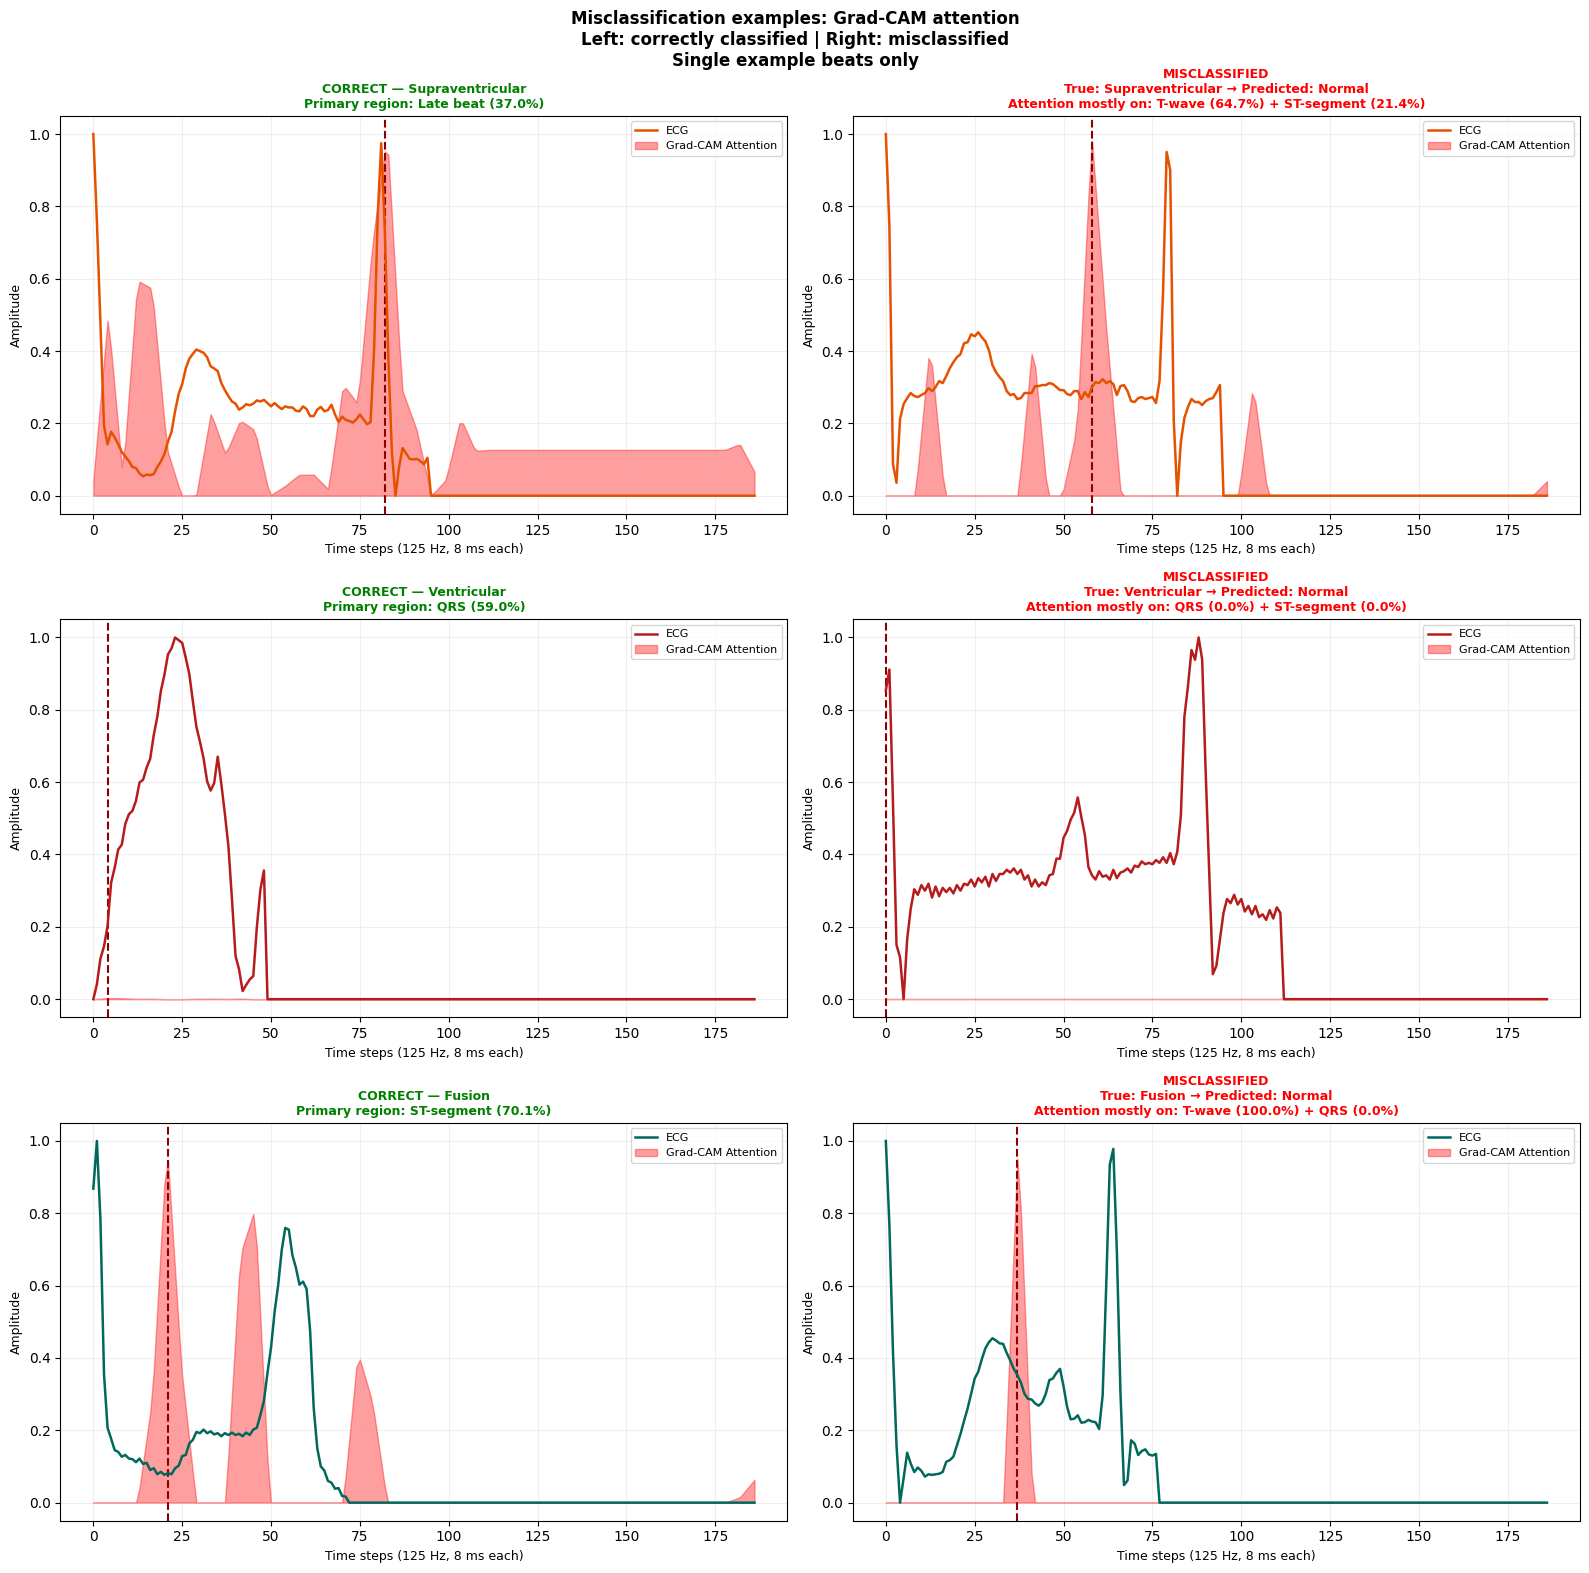

Misclassification analysis complete!


In [36]:
# ──────────────────────────────────────────────────────────────
# MISCLASSIFICATION ANALYSIS
#
# For each clinically critical class (SVT, Ventricular, Fusion),
# we show a correct vs misclassified sample side-by-side.
# The Grad-CAM heatmap reveals WHICH ECG region caused the error.
#
# These are single example beats, so treat them as illustrations, not statistics.
# ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 2, figsize=(16, 16))
fig.suptitle(
    'Misclassification examples: Grad-CAM attention\n'
    'Left: correctly classified | Right: misclassified\n'
    'Single example beats only',
    fontsize=12, fontweight='bold'
)

# Clinically critical classes only
target_classes = [1, 2, 3]  # SVT, Ventricular, Fusion
wrong_colors   = ['#E65100', '#B71C1C', '#00695C']

for row, (class_idx, color) in enumerate(zip(target_classes, wrong_colors)):
    idxs = np.where(y_test == class_idx)[0]
    correct_sample, wrong_sample = None, None

    for idx in idxs[:500]:
        pred = np.argmax(best_model.predict(
            tf.expand_dims(X_test[idx], 0), verbose=0))
        if pred == class_idx and correct_sample is None:
            correct_sample = (X_test[idx], class_idx)
        if pred != class_idx and wrong_sample is None:
            wrong_sample = (X_test[idx], pred)
        if correct_sample and wrong_sample:
            break

    for col, sample_data, is_wrong in [
            (0, correct_sample, False),
            (1, wrong_sample,   True)]:

        if sample_data is None:
            continue

        signal, pred_class = sample_data
        ax = axes[row][col]

        hmap, _  = grad_cam_1d(best_model, signal, class_idx)
        rim      = region_importance(hmap, signal)
        top      = max(rim, key=rim.get)
        second   = sorted(rim, key=rim.get, reverse=True)[1]

        sig_f = signal.flatten()
        smin  = sig_f.min()
        srng  = sig_f.max() - smin + 1e-8

        ax.plot(sig_f, color=color, linewidth=1.8, label='ECG', zorder=3)
        ax.fill_between(range(187), smin, smin + hmap * srng,
                        alpha=0.38, color='red', label='Grad-CAM Attention')
        ax.axvline(int(np.argmax(hmap)), color='darkred',
                   linestyle='--', linewidth=1.5)

        if is_wrong:
            # Misclassified: explain which region confused the model
            ax.set_title(
                f'MISCLASSIFIED\n'
                f'True: {CLASS_NAMES[class_idx]} → Predicted: {CLASS_NAMES[pred_class]}\n'
                f'Attention mostly on: {top} ({rim[top]:.1f}%) + {second} ({rim[second]:.1f}%)',
                fontsize=9, fontweight='bold', color='red'
            )
        else:
            ax.set_title(
                f'CORRECT — {CLASS_NAMES[class_idx]}\n'
                f'Primary region: {top} ({rim[top]:.1f}%)',
                fontsize=9, fontweight='bold', color='green'
            )

        ax.set_xlabel('Time steps (125 Hz, 8 ms each)', fontsize=9)
        ax.set_ylabel('Amplitude', fontsize=9)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig('fig5_misclassification_analysis.png', dpi=300, bbox_inches='tight')
plt.show()
print('Misclassification analysis complete!')

# **Region attention table**



=== MEAN GRAD-CAM ATTENTION PER REGION (%) ===
                  QRS  ST-segment  T-wave  Late beat
Class                                               
Normal           49.7        11.9    14.3       24.1
Supraventricular  9.8        27.4    30.3       32.4
Ventricular      30.8        11.6    23.9       22.6
Fusion            5.2        52.3    24.2       16.7
Unknown          13.6        33.2    16.0       17.2

Beats used (non-empty heatmap / correct beats found): {'Normal': (175, 200), 'Supraventricular': (151, 200), 'Ventricular': (172, 200), 'Fusion': (134, 137), 'Unknown': (185, 200)}


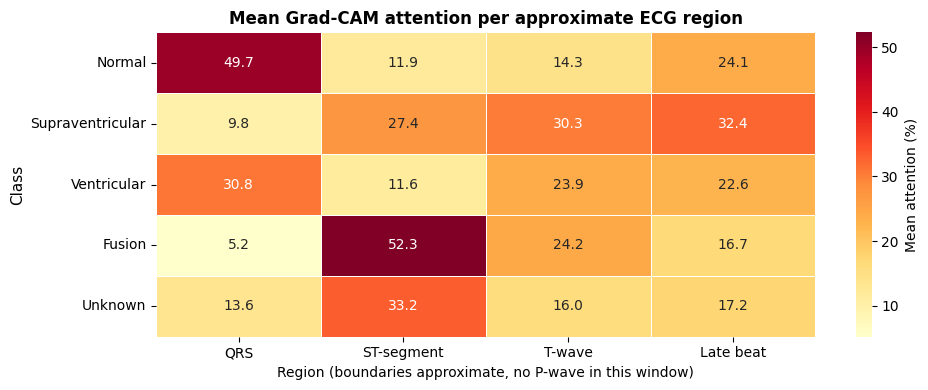

Saved fig6_region_attention_heatmap.png and region_attention_table.csv


In [37]:
# ──────────────────────────────────────────────────────────────
# REGION ATTENTION TABLE
# Mean Grad-CAM attention (%) per approximate ECG region, averaged over
# correctly classified test beats. Descriptive only: it shows where the model
# looks, it does not prove the model uses clinically correct features.
# ──────────────────────────────────────────────────────────────
if region_table:
    df_regions = pd.DataFrame(region_table).T
    df_regions.index.name = 'Class'

    print('\n=== MEAN GRAD-CAM ATTENTION PER REGION (%) ===')
    print(df_regions.to_string(float_format='{:.1f}'.format))
    print('\nBeats used (non-empty heatmap / correct beats found):', n_used)

    fig, ax = plt.subplots(figsize=(10, 4))
    sns.heatmap(df_regions, annot=True, fmt='.1f', cmap='YlOrRd',
                cbar_kws={'label': 'Mean attention (%)'}, linewidths=0.5, ax=ax)
    ax.set_title('Mean Grad-CAM attention per approximate ECG region', fontweight='bold', fontsize=12)
    ax.set_ylabel('Class', fontsize=11)
    ax.set_xlabel('Region (boundaries approximate, no P-wave in this window)', fontsize=10)
    plt.tight_layout()
    plt.savefig('fig6_region_attention_heatmap.png', dpi=300, bbox_inches='tight')
    plt.show()
    df_regions.to_csv('region_attention_table.csv')
    print('Saved fig6_region_attention_heatmap.png and region_attention_table.csv')


# **Save Best Model**

In [38]:
# ──────────────────────────────────────────────────────────────
# SAVE AND VERIFY BEST MODEL
# Saved in .keras format (TF 2.x native, preferred over .h5)
# Verification: run inference on 5 test samples to confirm
# the saved model produces correct predictions.
# ──────────────────────────────────────────────────────────────
save_path = f'/kaggle/working/final_best_model_{best_model_name.lower().replace(" ","_")}.keras'
best_model.save(save_path)
print(f'Saved: {save_path}')

# Verification round-trip
loaded_model = tf.keras.models.load_model(save_path)
sample_preds = np.argmax(loaded_model.predict(X_test[:5], verbose=0), axis=1)
actual       = y_test[:5]
print(f'\nVerification — Predicted: {[CLASS_NAMES[i] for i in sample_preds]}')
print(f'Verification — Actual:    {[CLASS_NAMES[i] for i in actual]}')
print('\n Model verified and working!')
print(f'\n All output files:')
import os
for f in sorted(os.listdir('/kaggle/working/')):
    size = os.path.getsize(f'/kaggle/working/{f}') / 1024
    print(f'   {f:<50s}  {size:>8.1f} KB')

Saved: /kaggle/working/final_best_model_cnn_baseline.keras

Verification — Predicted: ['Normal', 'Normal', 'Normal', 'Normal', 'Normal']
Verification — Actual:    ['Normal', 'Normal', 'Normal', 'Normal', 'Normal']

 Model verified and working!

 All output files:
   .virtual_documents                                       4.0 KB
   best_cnn.keras                                        2706.5 KB
   best_densenet.keras                                   3923.4 KB
   best_proposed.keras                                   5463.6 KB
   fig1_sample_beats.png                                  266.3 KB
   fig2_training_curves.png                               794.2 KB
   fig3_model_comparison.png                              206.2 KB
   fig4_gradcam_regions.png                              1262.8 KB
   fig5_misclassification_analysis.png                    936.6 KB
   fig6_region_attention_heatmap.png                      167.5 KB
   final_best_model_cnn_baseline.keras                   2706.5 KB

In [39]:
model.save('/kaggle/working/final_model.keras')

In [40]:
import os
import shutil

# List everything saved
files = os.listdir('/kaggle/working/')
print("Files saved:")
for f in files:
    size = os.path.getsize(f'/kaggle/working/{f}') / 1024
    print(f"  {f}  —  {size:.1f} KB")

Files saved:
  region_attention_table.csv  —  0.2 KB
  best_cnn.keras  —  2706.5 KB
  fig1_sample_beats.png  —  266.3 KB
  final_best_model_cnn_baseline.keras  —  2706.5 KB
  best_densenet.keras  —  3923.4 KB
  fig4_gradcam_regions.png  —  1262.8 KB
  .virtual_documents  —  4.0 KB
  fig3_model_comparison.png  —  206.2 KB
  fig6_region_attention_heatmap.png  —  167.5 KB
  final_model.keras  —  5463.6 KB
  fig2_training_curves.png  —  794.2 KB
  best_proposed.keras  —  5463.6 KB
  fig5_misclassification_analysis.png  —  936.6 KB


**Ablation study:** not completed. An earlier attempt failed (`l2` was not imported) and is removed here. No ablation results are claimed.
